In [5]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader # for image + table+ text kind of. data use --> unstructured.io libraries
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
from langchain_community.vectorstores import Chroma

from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from pydantic import BaseModel
from langgraph.prebuilt import ToolNode
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from typing import Annotated, operator
from langchain_core.tools import tool
from tavily import TavilyClient

load_dotenv()

True

In [6]:
# pip install tavily


In [8]:
# 1 load the pdf files
pdf_loader = PyPDFLoader("./documents/evs_oil_price_shock.pdf")
raw_docs = pdf_loader.load()

# 2 . split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = text_splitter.split_documents(raw_docs)
print(len(chunks))

embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
    # persist_directory="../chroma_db". # this is optional for this run
)

vectorstore.add_documents(chunks)


51


/var/folders/fq/kr6gv5l17pd4j572n0_n3f2c0000gn/T/ipykernel_2679/1201029246.py:12: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vectorstore = Chroma(


['b9918c11-86df-40f1-a1b0-071ac7f5b904',
 '0d95e14e-f809-4f2f-b505-8c2b571f87e2',
 '6341da7b-1661-47d9-bd65-ccbac6c4aa85',
 '57711148-bdde-4f72-ac13-331ffda81498',
 'da3bf387-acfa-4b12-9534-b77e14e4f0b3',
 'a44a2fe1-0aa6-4df1-b4c0-c8b657c77313',
 '3edc1cda-8df2-48b6-92a5-2201b3ba204d',
 '8226dc52-0b37-4826-89de-0d48351ed5cc',
 'ec352a25-b182-4f30-8a70-10bb2fe46cdf',
 'eb4125ad-9e96-4344-8cad-0019ce5b7e00',
 '67287dd5-c6f7-448c-a812-37342557604a',
 'a3696d4b-9536-48c6-bde4-c1d236795b31',
 '5dde1ee4-e6ac-4ab5-9e62-544c25bf6d8e',
 '9ab9c97b-9db2-46f0-aec2-764f02c2aa35',
 '2590d981-e2c3-499c-b00c-c34540ba4182',
 '43965857-3488-4265-a267-543724983819',
 '969db75f-2fd9-44aa-85b9-c78649ff6c8a',
 '6196ea8b-bd06-46d6-9b11-80c3607eda24',
 '5e54b8af-f6b8-46e6-92d8-5b30803a572c',
 '16a1e672-18fb-446f-93ce-6e5ff13f46bd',
 'd95d42ea-5b76-49f3-a085-2b133001b8ea',
 '237f4c02-e4a0-4fa4-aa65-770bdf1c563f',
 'c16f4a0e-cbb2-4216-a61b-42df5cd93d5d',
 '1ee076ac-9de3-4922-9db6-c857a1ffb8d6',
 'fa31ea75-b3ee-

In [9]:
llm = ChatOpenAI(model="gpt-4o-mini") # this is for route_questions and generation
agent_llm = ChatOpenAI(model="gpt-5-mini") 

In [17]:
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: Annotated[list[Document], operator.add]
    context: Annotated[str, operator.add]
    generation: str
    needs_retrieval: bool



class RouteDecision(BaseModel):
    needs_retrieval: bool

In [10]:
# Define the tools
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k:int = 3):
    """ 
    Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages.
    
    """

    retriever = vectorstore.as_retriever(search_kwargs={"k": k})
    docs = retriever.invoke(query)
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return context,docs


import os

@tool(response_format="content_and_artifact")
def web_search(query:str, max_results:int = 3):
    """
    Search the web for relevant information.
    Adjust max_results (default 3) to retrieve more or fewer results.
    """
    client = TavilyClient(api_key=os.getenv("TVLY_API_KEY"))
    response = client.search(query, max_results=max_results)
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return content, docs



In [15]:
tools = [web_search, vector_store_search]
agent_llm_with_tools = agent_llm.bind_tools(tools)
tool_node = ToolNode(tools)


In [ ]:
# agent_llm.invoke('tell me todays news')

AIMessage(content='I can’t fetch live news or browse the web, so I can’t pull “today’s” headlines directly. I can still help in a few useful ways — which would you like?\n\n1) Tell me the country or topics you care about (world, US, business, tech, sports, local) and I’ll summarize the most likely ongoing storylines and what to watch based on recent trends.  \n2) Paste one or more article links or headlines and I’ll summarize them and explain their significance.  \n3) I can point you to reliable sources and quick ways to get today’s headlines (apps, newsletters, podcasts), and set up a short daily briefing format you can use.\n\nQuick list of reliable sources and ways to get live headlines:\n- News aggregators: Google News, Apple News.  \n- Wire services: Reuters, Associated Press (AP) — fast, factual.  \n- Broadcasters: BBC, Al Jazeera, NPR.  \n- US papers: The New York Times, Washington Post; Financial Times, Bloomberg for markets.  \n- Podcasts for daily briefings: The Daily (NYT), 

In [18]:
def route_question(state: AgenticRAGState) -> dict:

    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])

    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})

    return {"needs_retrieval": decision.needs_retrieval}

In [19]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)

In [20]:
def agent(state: AgenticRAGState) -> dict:
    messages = state['messages']
    if not messages:
        messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=state["query"])]
        
    response = agent_llm_with_tools.invoke(messages)
    return {"messages": [response]}
    

def collect_tool_output(state: AgenticRAGState) -> dict:

    tool_messages = [m for m in state["messages"] if isinstance(m, ToolMessage)]
    all_docs, context_parts = [], []

    for msg in tool_messages:
        context_parts.append(msg.content)
        all_docs.extend(msg.artifact)

    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
    }

In [21]:
def generate(state: AgenticRAGState) -> dict:

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})

    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [22]:
from typing import Literal
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

In [23]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "agent")
graph_builder.add_edge("collect_tool_output", "generate")
graph_builder.add_edge("generate", END)


graph = graph_builder.compile()


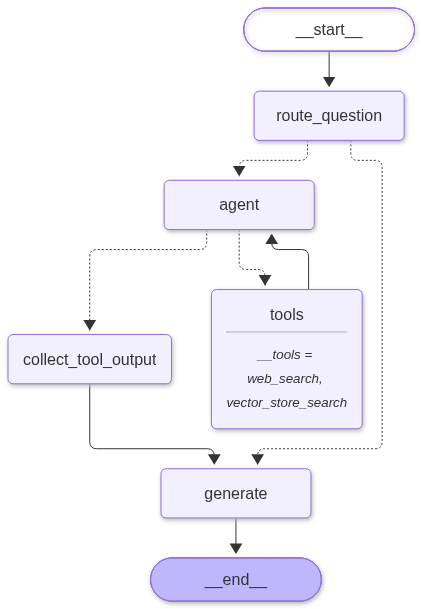

In [24]:
graph

In [25]:
query_vs = "According to the report, how will the adoption of electric vehicles impact oil demand?"

result_vs = graph.invoke({"query": query_vs, "messages": [], "retrieved_docs": [], "context": ""})

In [26]:
result_vs

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 127, 'prompt_tokens': 438, 'total_tokens': 565, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-Ek7clpzf2VdQhGZSBlYNCpqkwubXh', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1da23-3650-71c7-9c98-ab37f1fdb604-0', tool_calls=[{'name': 'vector_store_search', 'args': {'query': 'Adoption of electric vehicles impact on oil demand Will EVs Dampen the Oil Price Shock? oil demand displacement scenarios fleet turnover dynamics battery cost trends projections through 20

In [27]:
query_web = "What is the current temperature in New Delhi?"

result_web = graph.invoke({"query": query_web, "messages": [], "retrieved_docs": [], "context": ""})

In [28]:
result_web

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 99, 'prompt_tokens': 431, 'total_tokens': 530, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-Ek7doHCUgyZZnQYVNCoBkzkTCZjVX', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1da24-329a-7100-83af-c89568aee3a8-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'New Delhi current temperature now weather', 'max_results': 3}, 'id': 'call_Qd7cvaTLKLvMdq6jihvI2uHT', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 431, 'output_token